1. Suppress Warning Messages

In [ ]:
import warnings
warnings.filterwarnings('ignore')

2. Import Required Libraries and Machine Learning Tools

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

3. Load the Housing Dataset

In [ ]:
df = pd.read_csv("Housing_Dataset.csv")

4. Display the First Five Rows of the Dataset

In [ ]:
df.head()

,Area_SqFt,Rooms,Build_Year,Location,Street_Type,Furnishing,Property_Type,Has_Pool,Price
0,2473.192784,4.0,1992,Jaipur,Residential Lane,Furnished,Apartment,No,568486.0
1,2353.472711,4.0,2006,Indore,Corner Plot,Unfurnished,Apartment,Yes,577214.0
2,2212.222005,3.0,2012,Jaipur,Highway Facing,Semi-Furnished,Duplex,No,581300.0
3,2823.886596,6.0,1993,Lucknow,Main Road,Unfurnished,Villa,Yes,794614.0
4,1869.648721,5.0,2012,Jaipur,Corner Plot,Semi-Furnished,Apartment,No,493086.0


5. Display the Dataset Shape

In [ ]:
print(df.shape)
print("Shape of dataset:")


(1124, 9)
Shape of dataset:


6. Display the Dataset Column Names

In [ ]:
print("\nColumn names:")
print(df.columns)


Column names:
Index(['Area_SqFt', 'Rooms', 'Build_Year', 'Location', 'Street_Type',
       'Furnishing', 'Property_Type', 'Has_Pool', 'Price'],
      dtype='object')


7. Explore Dataset Information and Data Types

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1124 entries, 0 to 1123
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Area_SqFt      1091 non-null   float64
 1   Rooms          1091 non-null   float64
 2   Build_Year     1124 non-null   int64  
 3   Location       1124 non-null   object 
 4   Street_Type    1124 non-null   object 
 5   Furnishing     1091 non-null   object 
 6   Property_Type  1124 non-null   object 
 7   Has_Pool       1124 non-null   object 
 8   Price          1124 non-null   float64
dtypes: float64(3), int64(1), object(5)
memory usage: 79.2+ KB


8. Generate Descriptive Statistics

In [ ]:
df.describe()

,Area_SqFt,Rooms,Build_Year,Price
count,1091.000000,1091.000000,1124.000000,1.124000e+03
mean,2237.479473,4.568286,2005.080071,6.082015e+05
std,731.097828,1.678155,11.708876,1.431958e+05
min,700.000000,2.000000,1985.000000,2.486400e+05
25%,1834.022964,3.000000,1995.000000,5.161948e+05
50%,2201.545784,5.000000,2005.000000,6.025410e+05
75%,2576.139355,6.000000,2015.000000,6.895785e+05
max,10267.124330,7.000000,2024.000000,2.071402e+06


9. Check for Missing Values

In [ ]:
print(df.isnull().sum())
print("Missing values:")

Area_SqFt        33
Rooms            33
Build_Year        0
Location          0
Street_Type       0
Furnishing       33
Property_Type     0
Has_Pool          0
Price             0
dtype: int64
Missing values:


10. Visualize the Distribution of House Prices

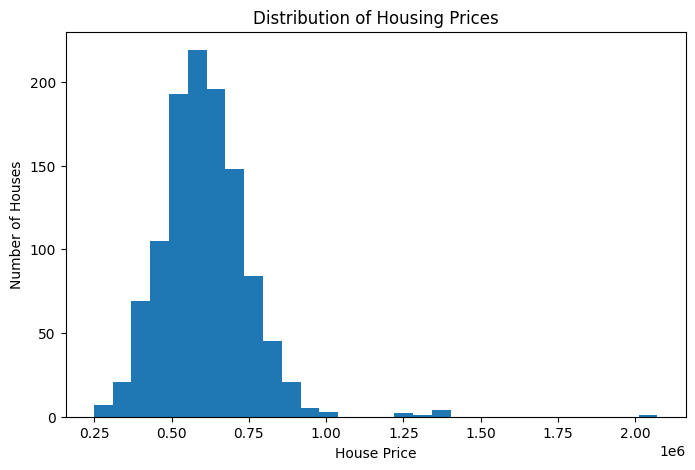

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df["Price"], bins=30)
plt.xlabel("House Price")
plt.ylabel("Number of Houses")
plt.title("Distribution of Housing Prices")
plt.show()


11. Visualize the Relationship Between Area and House Price

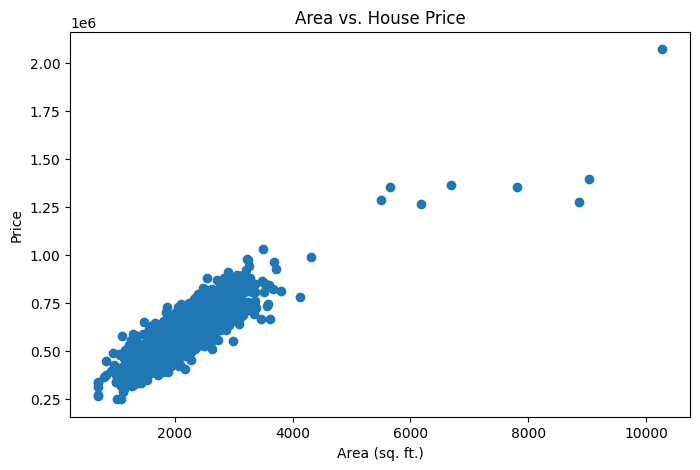

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Area_SqFt"], df["Price"])
plt.xlabel("Area (sq. ft.)")
plt.ylabel("Price")
plt.title("Area vs. House Price")
plt.show()

12. Separate Input Features and Target Variables

In [ ]:
X = df.drop("Price", axis=1)
y = df["Price"]

13. Identify Numerical and Categorical Features

In [ ]:
numerical_features = ["Area_SqFt", "Rooms", "Build_Year"]
categorical_features = ["Location", "Property_Type", "Furnishing", "Street_Type", "Has_Pool"]

14. Split the Dataset into Training and Testing Sets

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

15. Handle Missing Values, Encode Categorical Features, and Standardize    Numerical Features



In [ ]:
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

16. Create the Data Preprocessing Pipeline

In [ ]:
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

17. Build the Linear Regression Model Pipeline

In [ ]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

18. Train the Linear Regression Model

In [ ]:
model.fit(X_train, y_train)
print("Model Training COmpleted Successfully")

Model Training COmpleted Successfully


19. Predict House Prices on Test Data

In [ ]:
y_pred = model.predict(X_test)
print("Predictions:")
print(y_pred[:10])

Predictions:
[688894.92559785 615507.26943961 538460.76719757 552364.05486155
 584878.7961907  430202.09803331 696172.3176222  552335.33583172
 591901.48517634 688926.58789985]


20. Evaluate the Model using Mean Squared Error (MSE)

In [ ]:
mse = mean_squared_error(y_test, y_pred)
print("\nMean Squared Error:", mse)


Mean Squared Error: 1175303448.2528517


21. Visualize Actual Prices vs Preedict Prices

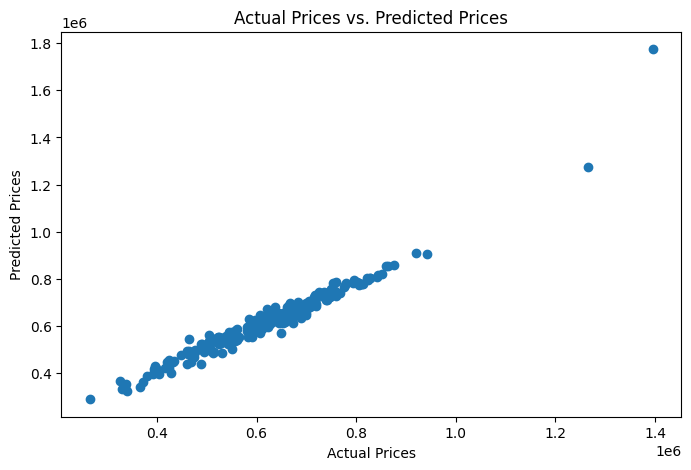

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual Prices vs. Predicted Prices")
plt.show()

22. Define Example Input Features for a New House

In [ ]:
#Example
#Area_SqFt=1400
#Rooms=3
#Build_Year=2005
#Location=Pune
#Street_Type=Residential
#Furnishing=Semi-furnished
#Property_Type=Apartment
#Has_Pool=Yes

23. Predict the Price of a New House

In [ ]:
new_house = pd.DataFrame([{
    "Area_SqFt": 1400,
    "Rooms": 3,
    "Build_Year": 2005,
    "Location": "Pune",
    "Street_Type": "Residential",
    "Furnishing": "Semi-furnished",
    "Property_Type": "Apartment",
    "Has_Pool": "No",
}])

predicted_price = model.predict(new_house)
print("\nPredicted House Price")
print("₹", round(predicted_price[0], 2), "Lakh")


Predicted House Price
₹ 388793.41 Lakh
